# Statistics & Hypothesis Testing — Implementation Cheatsheet

Theory: [statistics.md](statistics.md)

Real questions on the repo's datasets: **ExtraaLearn** (leads) and **SuperKart** (sales).

| # | Section |
|---|---|
| 1 | Descriptive statistics |
| 2 | Probability distributions (binomial, normal) |
| 3 | Central Limit Theorem |
| 4 | Confidence intervals |
| 5 | Hypothesis tests: the recipe |
| 6 | One-sample t-test |
| 7 | Two-sample t-test (+ assumption checks, Mann-Whitney) |
| 8 | Two-proportion z-test |
| 9 | Chi-square test of independence |
| 10 | One-way ANOVA + Tukey |

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.multicomp import pairwise_tukeyhsd

ALPHA = 0.05
leads = pd.read_csv("../data/extraalearn.csv")
sales = pd.read_csv("../data/superkart.csv")

def decide(p, alpha=ALPHA):
    return f"p = {p:.4f} -> " + ("REJECT H0 ✅ (significant)" if p < alpha else "fail to reject H0 (not significant)")

def check(p, assumption, alpha=ALPHA):
    """Assumption tests are read the other way around: H0 = 'the assumption holds'."""
    return f"{assumption}: p = {p:.4f} -> " + (f"VIOLATED ❌" if p < alpha else "OK ✅")

## 1. Descriptive statistics

In [2]:
x = leads["time_spent_on_website"]
print(f"mean {x.mean():.1f} | median {x.median():.1f} | mode {x.mode()[0]} | std {x.std():.1f} | var {x.var():.0f}")
print(f"Q1 {x.quantile(.25):.0f} | Q3 {x.quantile(.75):.0f} | IQR {x.quantile(.75) - x.quantile(.25):.0f} | range {x.max() - x.min()}")
print(f"skew {x.skew():.2f} (>0 = right tail) | kurtosis {x.kurt():.2f}")

mean 724.0 | median 376.0 | mode 0 | std 743.8 | var 553281
Q1 149 | Q3 1337 | IQR 1188 | range 2537
skew 0.95 (>0 = right tail) | kurtosis -0.58


## 2. Probability distributions
scipy.stats functions (same for every distribution):
- `pmf(k)` (discrete) / `pdf(x)` (continuous): probability (density) **at** a value
- `cdf(x)`: P(X ≤ x)
- `ppf(q)`: inverse of cdf: the value below which q% falls (percentiles, critical values)
- `rvs(size)`: random samples

P(X = 6)  = 0.192
P(X <= 3) = 0.107
P(X >= 10) = 0.048


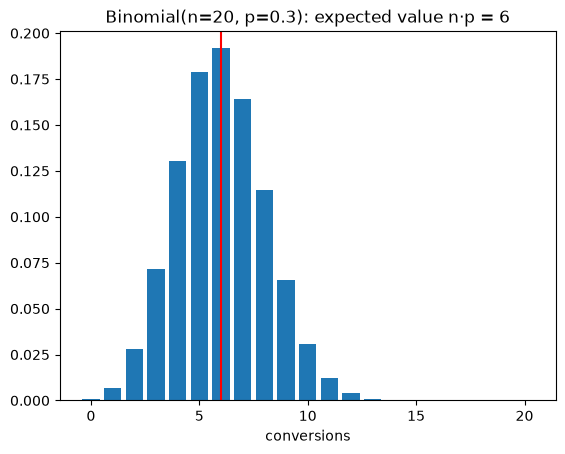

In [3]:
# Binomial: n independent yes/no trials with probability p.
# 30% of leads convert. Out of 20 leads:
n, p = 20, 0.30
print(f"P(X = 6)  = {stats.binom.pmf(6, n, p):.3f}")         # exactly 6
print(f"P(X <= 3) = {stats.binom.cdf(3, n, p):.3f}")         # at most 3
print(f"P(X >= 10) = {1 - stats.binom.cdf(9, n, p):.3f}")    # at least 10  ->  1 - cdf(k - 1)

k = np.arange(0, n + 1)
plt.bar(k, stats.binom.pmf(k, n, p)); plt.axvline(n * p, color="r")
plt.title("Binomial(n=20, p=0.3): expected value n·p = 6"); plt.xlabel("conversions"); plt.show()

In [4]:
# Normal: mean 30 min, std 5 min (pizza delivery example from the course)
mu, sigma = 30, 5
print(f"P(X < 25)        = {stats.norm.cdf(25, mu, sigma):.3f}")
print(f"P(25 < X < 35)   = {stats.norm.cdf(35, mu, sigma) - stats.norm.cdf(25, mu, sigma):.3f}   (empirical rule: 68%)")
print(f"P(20 < X < 40)   = {stats.norm.cdf(40, mu, sigma) - stats.norm.cdf(20, mu, sigma):.3f}   (95%)")
print(f"90th percentile  = {stats.norm.ppf(0.90, mu, sigma):.1f} min")
print(f"z-score of 38    = {(38 - mu) / sigma:.2f}")

P(X < 25)        = 0.159
P(25 < X < 35)   = 0.683   (empirical rule: 68%)
P(20 < X < 40)   = 0.954   (95%)
90th percentile  = 36.4 min
z-score of 38    = 1.60


## 3. Central Limit Theorem
Even if the data is **skewed**, the distribution of **sample means** is ~normal when n is large (≥ 30), with std = σ/√n (**standard error**).

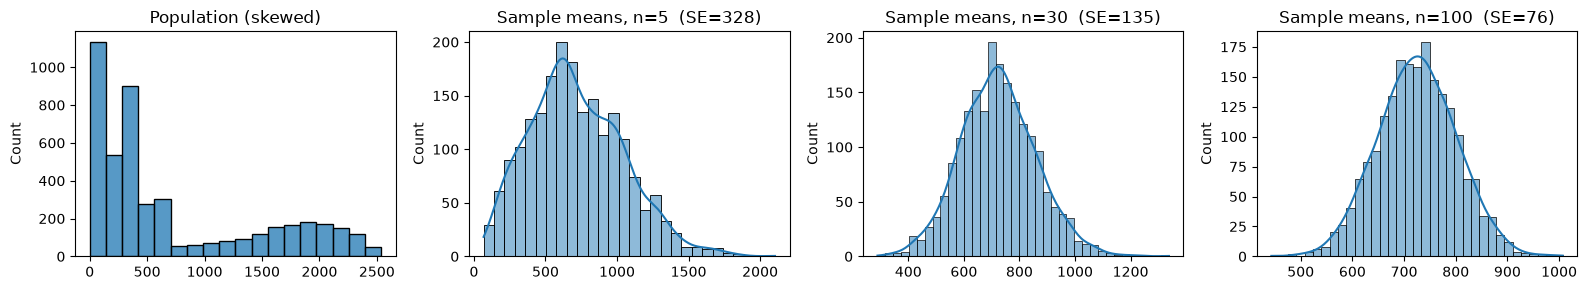

In [5]:
rng = np.random.default_rng(0)
population = leads["time_spent_on_website"].values
fig, ax = plt.subplots(1, 4, figsize=(16, 3))
sns.histplot(population, ax=ax[0]).set_title("Population (skewed)")
for a, size in zip(ax[1:], [5, 30, 100]):
    means = [rng.choice(population, size).mean() for _ in range(2000)]
    sns.histplot(means, kde=True, ax=a).set_title(f"Sample means, n={size}  (SE={np.std(means):.0f})")
plt.tight_layout(); plt.show()

## 4. Confidence intervals
95% CI for the mean = x̄ ± t(0.975, df=n−1) · s/√n. *If we repeated the sampling many times, 95% of the intervals would contain the true mean.*

In [6]:
sample = sales["Product_Store_Sales_Total"].sample(100, random_state=1)
ci = stats.t.interval(0.95, df=len(sample) - 1, loc=sample.mean(), scale=stats.sem(sample))
print(f"sample mean {sample.mean():.0f} | 95% CI ({ci[0]:.0f}, {ci[1]:.0f}) | true mean {sales['Product_Store_Sales_Total'].mean():.0f}")

sample mean 3369 | 95% CI (3133, 3606) | true mean 3464


## 5. Hypothesis tests: the recipe
1. **H0** (null: no effect / no difference) vs **Ha** (alternative: what you want to prove)
2. Choose **α** (usually 0.05) and the right **test** (see the table in [statistics.md](statistics.md#which-test))
3. Check the test's **assumptions**
4. Compute the **p-value** = P(seeing data this extreme **if H0 were true**)
5. **p < α → reject H0**. Otherwise fail to reject (≠ "H0 is true")

## 6. One-sample t-test
*Is the average product sales different from 3,500?*  H0: μ = 3500, Ha: μ ≠ 3500

In [7]:
t, p = stats.ttest_1samp(sales["Product_Store_Sales_Total"], popmean=3500)
print(f"mean = {sales['Product_Store_Sales_Total'].mean():.1f}, t = {t:.2f}")
print(decide(p))

mean = 3464.0, t = -3.16
p = 0.0016 -> REJECT H0 ✅ (significant)


## 7. Two-sample t-test (independent)
*Do converted leads spend more time on the website?*  H0: μ_conv = μ_not, Ha: μ_conv > μ_not (one-tailed)

In [8]:
conv = leads.loc[leads["status"] == 1, "time_spent_on_website"]
not_conv = leads.loc[leads["status"] == 0, "time_spent_on_website"]
print(f"means: converted {conv.mean():.0f} vs not {not_conv.mean():.0f}")

# Assumption checks
print(check(stats.shapiro(conv.sample(500, random_state=1)).pvalue, "Normality (Shapiro, on a sample)"))
print(check(stats.levene(conv, not_conv).pvalue, "Equal variances (Levene)"))

means: converted 1068 vs not 577
Normality (Shapiro, on a sample): p = 0.0000 -> VIOLATED ❌
Equal variances (Levene): p = 0.0000 -> VIOLATED ❌


In [9]:
# Variances differ -> Welch's t-test (equal_var=False). With large n the CLT makes the mean ~normal anyway.
t, p = stats.ttest_ind(conv, not_conv, equal_var=False, alternative="greater")
print(f"Welch t = {t:.2f}", "|", decide(p))

# Non-parametric alternative (no normality assumption): Mann-Whitney U
print("Mann-Whitney:", decide(stats.mannwhitneyu(conv, not_conv, alternative="greater").pvalue))

Welch t = 20.31 | p = 0.0000 -> REJECT H0 ✅ (significant)
Mann-Whitney: p = 0.0000 -> REJECT H0 ✅ (significant)


## 8. Two-proportion z-test
*Is the conversion rate different for leads whose first interaction was the Website vs the Mobile App?*

In [10]:
g = leads.groupby("first_interaction")["status"].agg(["sum", "count"])
g["rate"] = g["sum"] / g["count"]
print(g)
z, p = proportions_ztest(count=g["sum"].values, nobs=g["count"].values)
print(f"z = {z:.2f}", "|", decide(p))

                    sum  count      rate
first_interaction                       
Mobile App          218   2070  0.105314
Website            1159   2542  0.455940
z = -25.88 | p = 0.0000 -> REJECT H0 ✅ (significant)


## 9. Chi-square test of independence
*Is conversion related to the lead's occupation?*  H0: the two categorical variables are independent.

In [11]:
table = pd.crosstab(leads["current_occupation"], leads["status"])
chi2, p, dof, expected = stats.chi2_contingency(table)
print(table, f"\nchi2 = {chi2:.1f}, dof = {dof}")
print(decide(p))
print("All expected counts >= 5 (assumption):", (expected >= 5).all())

status                 0    1
current_occupation           
Professional        1687  929
Student              490   65
Unemployed          1058  383 
chi2 = 134.6, dof = 2
p = 0.0000 -> REJECT H0 ✅ (significant)
All expected counts >= 5 (assumption): True


## 10. One-way ANOVA (3+ groups)
*Is the mean sales the same for all store types?*  H0: all means equal. Ha: at least one differs.

In [12]:
groups = [grp["Product_Store_Sales_Total"].values for _, grp in sales.groupby("Store_Type")]
print(check(stats.levene(*groups).pvalue, "Equal variances (Levene)"))
f, p = stats.f_oneway(*groups)
print(f"ANOVA F = {f:.1f}", "|", decide(p))

# Variances differ -> confirm with the non-parametric Kruskal-Wallis (compares medians/ranks)
print("Kruskal-Wallis:", decide(stats.kruskal(*groups).pvalue))

Equal variances (Levene): p = 0.0000 -> VIOLATED ❌
ANOVA F = 6193.8 | p = 0.0000 -> REJECT H0 ✅ (significant)
Kruskal-Wallis: p = 0.0000 -> REJECT H0 ✅ (significant)


ANOVA only says *some* mean differs. **Tukey HSD** tells **which pairs** differ (controlling the error rate across many comparisons).

In [13]:
print(pairwise_tukeyhsd(sales["Product_Store_Sales_Total"], sales["Store_Type"], alpha=ALPHA))

               Multiple Comparison of Means - Tukey HSD, FWER=0.05                
      group1             group2       meandiff  p-adj   lower      upper    reject
----------------------------------------------------------------------------------
Departmental Store         Food Mart -3184.0239   0.0 -3246.2086 -3121.8391   True
Departmental Store Supermarket Type1 -1023.1875   0.0 -1080.5999  -965.7751   True
Departmental Store Supermarket Type2 -1647.6542   0.0 -1695.5607 -1599.7477   True
         Food Mart Supermarket Type1  2160.8363   0.0  2100.8299  2220.8428   True
         Food Mart Supermarket Type2  1536.3696   0.0  1485.3831  1587.3562   True
 Supermarket Type1 Supermarket Type2  -624.4667   0.0  -669.5096  -579.4238   True
----------------------------------------------------------------------------------
